--- Y Ý 1: Hồi quy tuyến tính đơn giản ---
Phương trình: y = 31.71x + -78.10
Dự đoán giá cho nhà 75 m2: 2300.48 triệu VND

--- Ý 2: Thêm dữ liệu và độ nhiễu ---
Phương trình (có nhiễu): y = 29.14x + 266.75

--- Ý 3: Hồi quy đa biến (Thêm biến) ---
Hệ số góc cho các biến [Diện tích, Số phòng, Khoảng cách]:
[ 24.0947757  112.698487   -37.08633929]
Hệ số chặn b: 389.75


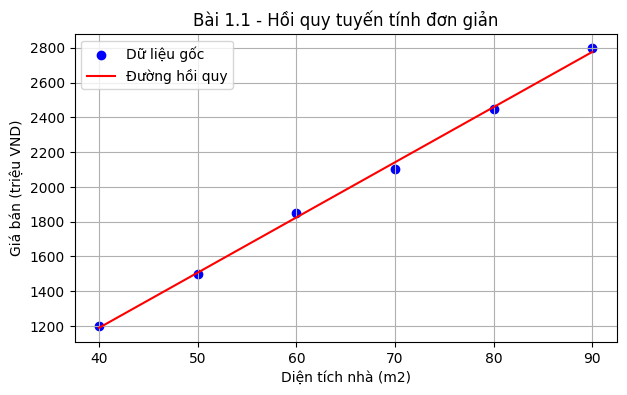

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression


print("--- Y Ý 1: Hồi quy tuyến tính đơn giản ---")
X_p1 = np.array([40, 50, 60, 70, 80, 90]).reshape(-1, 1)
y_p1 = np.array([1200, 1500, 1850, 2100, 2450, 2800])

model_p1 = LinearRegression()
model_p1.fit(X_p1, y_p1)

print(f"Phương trình: y = {model_p1.coef_[0]:.2f}x + {model_p1.intercept_:.2f}")
gia_du_doan = model_p1.predict(np.array([[75]]))
print(
    "Dự đoán giá cho nhà 75 m2:", round(gia_du_doan[0], 2), "triệu VND\n"
)


print("--- Ý 2: Thêm dữ liệu và độ nhiễu ---")
np.random.seed(42)
n_samples = 100
dien_tich_p2 = np.random.uniform(40, 120, n_samples)
noise = np.random.normal(0, 150, n_samples)
gia_p2 = 30 * dien_tich_p2 + 200 + noise

X_p2 = dien_tich_p2.reshape(-1, 1)
model_p2 = LinearRegression().fit(X_p2, gia_p2)

print(
    f"Phương trình (có nhiễu): y = {model_p2.coef_[0]:.2f}x +"
    f" {model_p2.intercept_:.2f}\n"
)


print("--- Ý 3: Hồi quy đa biến (Thêm biến) ---")
so_phong = np.random.randint(1, 5, n_samples)  # Số phòng ngủ
khoang_cach = np.random.uniform(1, 15, n_samples)  # Khoảng cách trung tâm


X_p3 = np.column_stack((dien_tich_p2, so_phong, khoang_cach))
y_p3 = 25 * dien_tich_p2 + 100 * so_phong - 30 * khoang_cach + 300 + noise

model_p3 = LinearRegression().fit(X_p3, y_p3)
print("Hệ số góc cho các biến [Diện tích, Số phòng, Khoảng cách]:")
print(model_p3.coef_)
print(f"Hệ số chặn b: {model_p3.intercept_:.2f}")


plt.figure(figsize=(7, 4))
plt.scatter(X_p1, y_p1, color="blue", label="Dữ liệu gốc")
x_line = np.linspace(40, 90, 100).reshape(-1, 1)
y_line = model_p1.predict(x_line)
plt.plot(x_line, y_line, color="red", label="Đường hồi quy")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.title("Bài 1.1 - Hồi quy tuyến tính đơn giản")
plt.legend()
plt.grid(True)
plt.show()

Do chinh xac: 0.84

Ma tran nham lan:
[[ 80  24]
 [ 16 130]]

10 mau dau tien trong tap test:
BMI=29.19, Nhan thuc te=1, Xac suat nhan 1=0.718, Nhan du doan=1
BMI=36.72, Nhan thuc te=1, Xac suat nhan 1=0.972, Nhan du doan=1
BMI=32.42, Nhan thuc te=1, Xac suat nhan 1=0.887, Nhan du doan=1
BMI=29.77, Nhan thuc te=1, Xac suat nhan 1=0.757, Nhan du doan=1
BMI=23.45, Nhan thuc te=0, Xac suat nhan 1=0.255, Nhan du doan=0
BMI=19.63, Nhan thuc te=0, Xac suat nhan 1=0.083, Nhan du doan=0
BMI=33.54, Nhan thuc te=1, Xac suat nhan 1=0.921, Nhan du doan=1
BMI=24.36, Nhan thuc te=0, Xac suat nhan 1=0.320, Nhan du doan=0
BMI=29.53, Nhan thuc te=1, Xac suat nhan 1=0.741, Nhan du doan=1
BMI=16.59, Nhan thuc te=0, Xac suat nhan 1=0.030, Nhan du doan=0


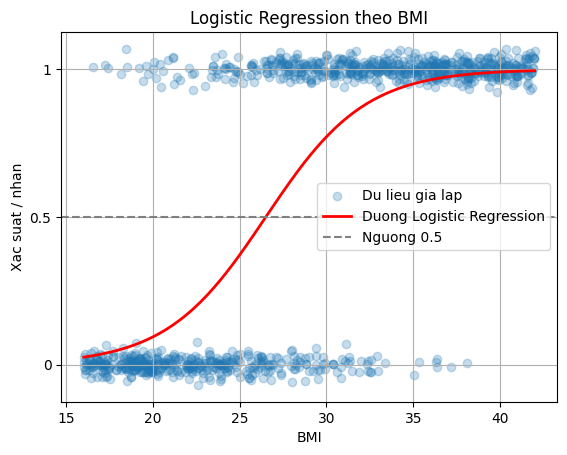

In [ ]:

#Bai2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix


rng = np.random.default_rng(42)

n = 1000

BMI = rng.uniform(16, 42, n)


xac_suat = 1 / (1 + np.exp(-(BMI - 27) / 2.8))


Mac_benh = rng.binomial(1, xac_suat)


X = BMI.reshape(-1, 1)
y = Mac_benh


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)


y_proba = model.predict_proba(X_test)[:, 1]


accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Do chinh xac:", round(accuracy, 4))
print("\nMa tran nham lan:")
print(cm)


print("\n10 mau dau tien trong tap test:")

for i in range(min(10, len(X_test))):
    print(
        f"BMI={X_test[i, 0]:.2f}, "
        f"Nhan thuc te={y_test[i]}, "
        f"Xac suat nhan 1={y_proba[i]:.3f}, "
        f"Nhan du doan={y_pred[i]}"
    )


BMI_grid = np.linspace(BMI.min(), BMI.max(), 300).reshape(-1, 1)


prob_grid = model.predict_proba(BMI_grid)[:, 1]

plt.scatter(
    BMI,
    Mac_benh + rng.normal(0, 0.025, n),
    alpha=0.25,
    label="Du lieu gia lap"
)

plt.plot(
    BMI_grid[:, 0],
    prob_grid,
    color="red",
    linewidth=2,
    label="Duong Logistic Regression"
)

plt.axhline(0.5, color="gray", linestyle="--", label="Nguong 0.5")

plt.xlabel("BMI")
plt.ylabel("Xac suat / nhan")
plt.title("Logistic Regression theo BMI")
plt.yticks([0, 0.5, 1], ["0", "0.5", "1"])
plt.legend()
plt.grid(True)
plt.show()

So mau du lieu: 442
So bien dau vao: 10
Ten cac bien: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

So mau train: 353
So mau test: 89

KET QUA DANH GIA
MSE: 2900.19
R2: 0.4526

SO SANH THUC TE VA DU DOAN
Thuc te: 219.00 | Du doan: 139.55
Thuc te: 70.00 | Du doan: 179.52
Thuc te: 202.00 | Du doan: 134.04
Thuc te: 230.00 | Du doan: 291.42
Thuc te: 111.00 | Du doan: 123.79
Thuc te: 84.00 | Du doan: 92.17
Thuc te: 242.00 | Du doan: 258.23
Thuc te: 272.00 | Du doan: 181.34
Thuc te: 94.00 | Du doan: 90.22
Thuc te: 96.00 | Du doan: 108.63


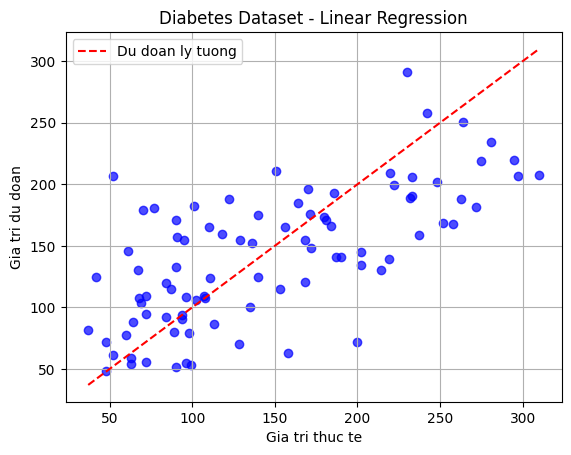

In [ ]:
# BAI 3: LINEAR REGRESSION VOI DU LIEU DIABETES



import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


data = load_diabetes()

X = data.data
y = data.target

print("So mau du lieu:", X.shape[0])
print("So bien dau vao:", X.shape[1])
print("Ten cac bien:", data.feature_names)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nSo mau train:", len(X_train))
print("So mau test:", len(X_test))


model = LinearRegression()


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKET QUA DANH GIA")
print("MSE:", round(mse, 2))
print("R2:", round(r2, 4))


print("\nSO SANH THUC TE VA DU DOAN")

for i in range(min(10, len(y_test))):
    print(
        f"Thuc te: {y_test[i]:.2f} | "
        f"Du doan: {y_pred[i]:.2f}"
    )


plt.scatter(y_test, y_pred, alpha=0.7, color="blue")


min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Du doan ly tuong"
)

plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.title("Diabetes Dataset - Linear Regression")
plt.legend()
plt.grid(True)
plt.show()